**¿Existen grupos de agentes del Mercado Eléctrico Mayorista con patrones de demanda mensual similares (en nivel, estacionalidad y variabilidad), y en qué medida esos grupos coinciden con categorías reales del sistema eléctrico (tipo de agente, región)?**

----------------------------------

**Base original** (CAMMESA, demanda mensual por agente) y limpieza: demanda de texto a número y mes a fecha.

↓

**Tabla intermedia** con agente + mes + demanda.

↓

**Ventana temporal común:** año 2024, con los agentes que tienen demanda positiva en los 12 meses (474 agentes).

↓

**Variables por agente** (a partir de feature engineering): nivel de demanda (`log_demanda_media`), variabilidad (`cv`) e índice estacional verano–invierno (`ind_estacional`). Se descartó el factor de carga por su correlación con el cv.

↓

**Revisión de la tabla de agentes:** valores atípicos y agentes con demanda intermitente (se conservan, con justificación), correlaciones, transformación log de cv y escalado con `RobustScaler`.

↓

**Modelo no supervisado (K-Means):** evaluación de k con el método del codo y la comparación de perfiles, interpretación de los clusters en unidades originales, visualización con PCA y prueba de estabilidad.

↓

**Comparar los integrantes de cada cluster con los tipos de agente reales.**

↓

**Modelo supervisado:** clasificar el tipo de agente con las mismas variables (se usa CV sin transformar)(regresión logística, árbol de decisión y Random Forest, con validación cruzada).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.decomposition import PCA

RANDOM_STATE = 42

**1-BASE DE DATOS ORIGINAL**

In [3]:
##Traemos la base de datos que vamos a usar

df = pd.read_csv('DF - Hoja 1.csv')

In [4]:
df.head(15)

,AÑO,MES,AGENTE NEMO,AGENTE DESCRIPCION,TIPO AGENTE,REGION,PROVINCIA,CATEGORIA AREA,CATEGORIA DEMANDA,CATEGORIA TARIFA,TARIFA,TIPO DEMANDA,DEMANDA [MWh]
0,2022,1/1/2022,AARGTAOY,AEROP ARG 2000 - Aeroparque,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"1.537,96"
1,2022,1/1/2022,ABRILHCY,ABRIL CLUB DE CAMPO,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"1.676,53"
2,2022,1/1/2022,ACARQQ3Y,ASOC.COOP.ARG. - Quequén,GU,BUENOS AIRES,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"374,89"
3,2022,1/1/2022,ACARSLSY,ASOC.COOP.ARG. - San Lorenzo,GU,LITORAL,SANTA FE,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"299,14"
4,2022,1/1/2022,ACERBR1Y,ACERBRAG-Bragado,GU,BUENOS AIRES,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"20.723,27"
5,2022,1/1/2022,ACINTBOY,ACINDAR PTA. TABLADA,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"1.624,82"
6,2022,1/1/2022,ACINVCSZ,ACINDAR PTA. V. CONSTITUCION,GU,LITORAL,SANTA FE,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"46.166,75"
7,2022,1/1/2022,ACUYLCMY,ACEROS CUYANOS S.A.- L.DE CUYO,GU,CUYO,MENDOZA,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"476,74"
8,2022,1/1/2022,AEEZECCY,AEROP ARG 2000 EX FAA EZEIZA,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"4.034,09"
9,2022,1/1/2022,AGEABACY,ARTE GRAFICO EDIT. ARG. SA,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"934,34"


**2-EDA**

In [5]:
##Dimensiones de la base de datos original

df.shape

(56696, 13)

In [6]:
##Nulos por columna

df.isnull().sum()

AÑO                   0
MES                   0
AGENTE NEMO           0
AGENTE DESCRIPCION    0
TIPO AGENTE           0
REGION                0
PROVINCIA             0
CATEGORIA AREA        0
CATEGORIA DEMANDA     0
CATEGORIA TARIFA      0
TARIFA                0
TIPO DEMANDA          0
DEMANDA [MWh]         0
dtype: int64

No hay columnas sin datos, pero hay que revisar si son datos válidos.

In [7]:
##Cantidad de categrorías de variables por columnas

df.nunique()

AÑO                       4
MES                      47
AGENTE NEMO             557
AGENTE DESCRIPCION      547
TIPO AGENTE               5
REGION                    9
PROVINCIA                22
CATEGORIA AREA           11
CATEGORIA DEMANDA         2
CATEGORIA TARIFA          3
TARIFA                   18
TIPO DEMANDA              5
DEMANDA [MWh]         51101
dtype: int64

La base tiene 56.696 filas y 13 columnas, sin valores nulos. Contiene 557 agentes distintos y 47 meses (de enero de 2022 a noviembre de 2025). Cada fila corresponde a un agente, un mes y una categoría de demanda o tarifa, por lo que un mismo agente puede tener varias filas en el mismo mes. Hay 5 tipos de agente, 9 regiones y 3 categorías tarifarias.

**DICCIONARIO**

**NEMO** = identificador alfanumérico único que se le asigna a cada agente inscripto en el Mercado Eléctrico Mayorista (MEM) para registrar sus transacciones, consumos o inyecciones de energía.

**DESCRIPCION** = nombre completo del agente.



In [8]:
##TIPO DE AGENTE = clasificación según rol en el mercado.

df['TIPO AGENTE'].unique()

<StringArray>
['GU', 'AG', 'DI', 'AR', 'DM']
Length: 5, dtype: str

GU: Gran Usuario

DI: Distribuidor

AG y AR: Autogeneradores


In [9]:
##REGION

df['REGION'].unique()

<StringArray>
[ 'GRAN BS.AS.', 'BUENOS AIRES',      'LITORAL',         'CUYO',
      'NORESTE',      'COMAHUE',     'NOROESTE',       'CENTRO',
   'PATAGONICA']
Length: 9, dtype: str

In [10]:
##PROVINCIA

df['PROVINCIA'].unique()

<StringArray>
[  'BUENOS AIRES',       'SANTA FE',        'MENDOZA',       'MISIONES',
       'LA PAMPA',          'SALTA',        'CORDOBA',        'TUCUMAN',
      'CATAMARCA',       'SAN LUIS',          'JUJUY',         'CHUBUT',
        'NEUQUEN',      'RIO NEGRO',     'ENTRE RIOS',       'LA RIOJA',
 'SGO.DEL ESTERO',       'SAN JUAN',     'CORRIENTES',          'CHACO',
     'SANTA CRUZ',        'FORMOSA']
Length: 22, dtype: str

In [11]:
##CATEGORIA AREA = distribuidora/zona.

df['CATEGORIA AREA'].unique()

<StringArray>
['Gran Usuario MEM',            'Resto',       'Entre Rios',
          'Mendoza',           'Edeaba',             'Eden',
           'Edenor',           'Edesur',          'Tucuman',
          'Cordoba',         'Santa Fe']
Length: 11, dtype: str

In [12]:
##CATEGORIA DEMANDA = clasif. según demanda mayorista.

df['CATEGORIA DEMANDA'].unique()

<StringArray>
['Gran Usuario', 'Distribuidor']
Length: 2, dtype: str

In [13]:
##CATEGORIA TARIFA = segmento tarifario.

df['CATEGORIA TARIFA'].unique()

<StringArray>
['Industrial/Comercial Grande', 'Comercial', 'Residencial']
Length: 3, dtype: str

In [14]:
##TARIFA = tarifa específica aplicada.

df['TARIFA'].unique()

<StringArray>
[                        'GUMAS/AUTOGENERADORES',
         'TARIFA USUARIO NO RESIDENCIAL <300KWH',
        'TARIFA USUARIO NO RESIDENCIAL >=300KWH',
  'TARIFA USUARIO NO RESIDENCIAL >=300KWH S Y E',
                                   'RESIDENCIAL',
 'TARIFA BASE ELECTRODEPEND Y BOMBEROS VOLUNTAR',
                                   'GUMES/GUPAS',
                           'RESIDENCIAL NIVEL 1',
                           'RESIDENCIAL NIVEL 2',
                      'RESIDENCIAL NIVEL 3 BASE',
                 'RESIDENCIAL NIVEL 3 EXCEDENTE',
        'CLUBES DE BARRIO Y PRODUCCION AGRICOLA',
 'TARIFA USU.NO RES. HASTA 10 KW Y > 800KWH/MES',
  'TARIFA USU.NO RES. HASTA 10KW Y <=800KWH/MES',
    'TARIFA USUARIO NO RES.>10 KW Y < DE 300 KW',
                             'Alumbrado Publico',
                      'RESIDENCIAL NIVEL 2 BASE',
                 'RESIDENCIAL NIVEL 2 EXCEDENTE']
Length: 18, dtype: str

In [15]:
##TIPO DEMANDA = clasif. según demanda mayorista.

df['TIPO DEMANDA'].unique()

<StringArray>
[                            'GUMA', 'No Residencial (ESTACIONALIZADA)',
                             'GUDI',    'Residencial (ESTACIONALIZADA)',
                             'GUME']
Length: 5, dtype: str

**TIPOS DE DATOS**

In [16]:
df.dtypes

AÑO                   int64
MES                     str
AGENTE NEMO             str
AGENTE DESCRIPCION      str
TIPO AGENTE             str
REGION                  str
PROVINCIA               str
CATEGORIA AREA          str
CATEGORIA DEMANDA       str
CATEGORIA TARIFA        str
TARIFA                  str
TIPO DEMANDA            str
DEMANDA [MWh]           str
dtype: object

In [17]:
df['DEMANDA [MWh]'].head(10)

0       1.537,96 
1       1.676,53 
2         374,89 
3         299,14 
4      20.723,27 
5       1.624,82 
6      46.166,75 
7         476,74 
8       4.034,09 
9         934,34 
Name: DEMANDA [MWh], dtype: str

In [18]:
## Transformación de DEMANDA a número. En la base original viene como texto y algunos meses tienen el valor "-".
## Se quitan los espacios, se elimina el punto de miles y se cambia la coma decimal por punto.
## Los valores "-" no se pueden convertir y se reemplazan por 0: se interpreta que ese mes el agente no tuvo demanda (si no hubiera dato, la fila no existiría, porque es una base de demanda mensual).

if not pd.api.types.is_numeric_dtype(df['DEMANDA [MWh]']):
    df['DEMANDA [MWh]'] = (
        df['DEMANDA [MWh]']
        .astype(str)
        .str.strip()
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
    df['DEMANDA [MWh]'] = pd.to_numeric(df['DEMANDA [MWh]'], errors='coerce').fillna(0)
    df['DEMANDA [MWh]'] = df['DEMANDA [MWh]'].astype('float64')

print(df['DEMANDA [MWh]'].dtype)
print("Nulos: ", df['DEMANDA [MWh]'].isnull().sum())
df['DEMANDA [MWh]'].head(10)


float64
Nulos:  0


0     1537.96
1     1676.53
2      374.89
3      299.14
4    20723.27
5     1624.82
6    46166.75
7      476.74
8     4034.09
9      934.34
Name: DEMANDA [MWh], dtype: float64

In [19]:
Porcentaje_Nulos = 100*(df['DEMANDA [MWh]'].isnull().sum())/len(df['DEMANDA [MWh]'])
print(Porcentaje_Nulos,"%")

## Verificamos que no quedaron nulos después de la conversión.

0.0 %


In [20]:
##Transformación de MES a formato fecha

df['MES'] = pd.to_datetime(df['MES'], format='%d/%m/%Y')
df['MES'].unique()

<DatetimeArray>
['2022-01-01 00:00:00', '2022-02-01 00:00:00', '2022-03-01 00:00:00',
 '2022-04-01 00:00:00', '2022-05-01 00:00:00', '2022-06-01 00:00:00',
 '2022-07-01 00:00:00', '2022-08-01 00:00:00', '2022-09-01 00:00:00',
 '2022-10-01 00:00:00', '2022-11-01 00:00:00', '2022-12-01 00:00:00',
 '2023-01-01 00:00:00', '2023-02-01 00:00:00', '2023-03-01 00:00:00',
 '2023-04-01 00:00:00', '2023-05-01 00:00:00', '2023-06-01 00:00:00',
 '2023-07-01 00:00:00', '2023-08-01 00:00:00', '2023-09-01 00:00:00',
 '2023-10-01 00:00:00', '2023-11-01 00:00:00', '2023-12-01 00:00:00',
 '2024-01-01 00:00:00', '2024-02-01 00:00:00', '2024-03-01 00:00:00',
 '2024-04-01 00:00:00', '2024-05-01 00:00:00', '2024-06-01 00:00:00',
 '2024-07-01 00:00:00', '2024-08-01 00:00:00', '2024-09-01 00:00:00',
 '2024-10-01 00:00:00', '2024-11-01 00:00:00', '2024-12-01 00:00:00',
 '2025-01-01 00:00:00', '2025-02-01 00:00:00', '2025-03-01 00:00:00',
 '2025-04-01 00:00:00', '2025-05-01 00:00:00', '2025-06-01 00:00:00',
 '20

**TABLA INTERMEDIA DE AGENTE+MES+DEMANDA [AMD]**

In [21]:
## Un mismo agente puede tener varias filas por mes (por categoría o tarifa), así que se suman.

AMD = df.groupby(['AGENTE NEMO', 'MES'], as_index= False)['DEMANDA [MWh]'].sum()
display(AMD)

,AGENTE NEMO,MES,DEMANDA [MWh]
0,AARGTAOY,2022-01-01,1537.96
1,AARGTAOY,2022-02-01,1201.69
2,AARGTAOY,2022-03-01,1246.53
3,AARGTAOY,2022-04-01,1098.70
4,AARGTAOY,2022-05-01,1186.89
...,...,...,...
22802,YPFTREUA,2022-06-01,0.00
22803,YPFTREUA,2022-07-01,0.00
22804,YPFTREUA,2022-08-01,0.00
22805,YPFTREUA,2022-09-01,0.00


In [22]:
AMD.shape

(22807, 3)

In [23]:
## Cuántos meses distintos tiene cada agente. El máximo posible es 47; algunos agentes tienen menos.

meses_por_agente = AMD.groupby('AGENTE NEMO')['MES'].nunique()
meses_por_agente

AGENTE NEMO
AARGTAOY    47
ABRILHCY    47
ACARQQ3Y    47
ACARSLSY    47
ACERBR1Y    47
            ..
YPFPHUQA    47
YPFPTRZZ    47
YPFSECZY    47
YPFTORUZ    47
YPFTREUA    10
Name: MES, Length: 557, dtype: int64

**DEMANDA AGREGADA**

La curva muestra la demanda mensual total de todos los agentes del MEM. Permite observar el patrón estacional del sistema y la evolución de la demanda a lo largo del período.

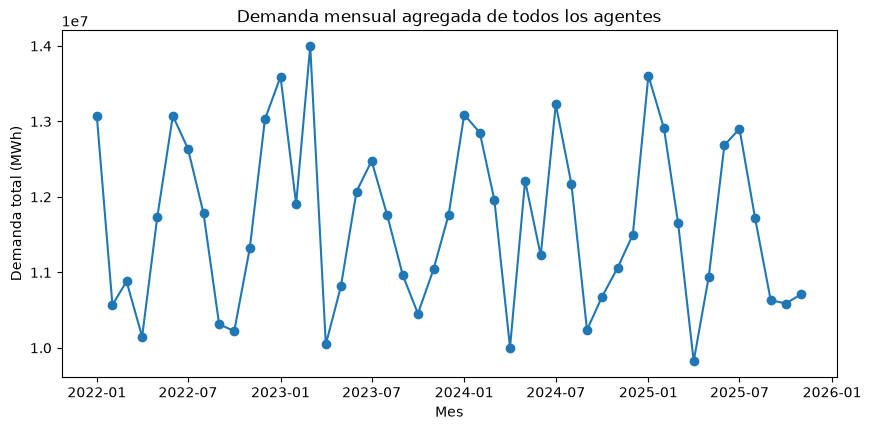

In [24]:
demanda_total = AMD.groupby('MES')['DEMANDA [MWh]'].sum()

plt.figure(figsize=(10, 4.5))
plt.plot(demanda_total.index, demanda_total.values, 'o-')
plt.xlabel('Mes')
plt.ylabel('Demanda total (MWh)')
plt.title('Demanda mensual agregada de todos los agentes')
plt.show()

La demanda agregada del sistema presenta un patrón estacional que se repite todos los años, con dos picos (verano, alrededor de enero y febrero, e invierno, alrededor de junio y julio) y dos valles (abril y septiembre–octubre). Todos los años muestran el mismo ciclo. Los picos de verano e invierno son de magnitud similar. 


**Identificamos posibles ventanas temporales para analizar**

In [25]:
## Identificamos cuántos agentes tienen registro en todos los meses de cada ventana y demanda promedio mayor a cero.

def agentes_con_ventana_temporal(inicio, fin):
    ventana = AMD[(AMD['MES'] >= inicio) & (AMD['MES'] <= fin)]

    # Cuántos meses tiene la ventana (12)
    n_meses = len(pd.date_range(inicio, fin, freq='MS'))

    # Agentes que tienen todos los meses de la ventana
    meses = ventana.groupby('AGENTE NEMO')['MES'].nunique()
    con_todos_los_meses = meses[meses == n_meses].index

    # Agentes con demanda promedio mayor a cero dentro de la ventana
    media = ventana.groupby('AGENTE NEMO')['DEMANDA [MWh]'].mean()
    con_demanda = media[media > 0].index

    return con_todos_los_meses.intersection(con_demanda)

print("Año 2022:", len(agentes_con_ventana_temporal('2022-01-01', '2022-12-01')))
print("Año 2023:", len(agentes_con_ventana_temporal('2023-01-01', '2023-12-01')))
print("Año 2024:", len(agentes_con_ventana_temporal('2024-01-01', '2024-12-01')))
print("Dic 2024 a nov 2025:", len(agentes_con_ventana_temporal('2024-12-01', '2025-11-01')))

Año 2022: 454
Año 2023: 468
Año 2024: 474
Dic 2024 a nov 2025: 477


In [26]:
##el año con más datos es el 2024

inicio = '2024-01-01'
fin = '2024-12-01'

agentes_ventana = agentes_con_ventana_temporal(inicio, fin)

AMD_ventana = AMD[
    (AMD['AGENTE NEMO'].isin(agentes_ventana)) &
    (AMD['MES'] >= inicio) &
    (AMD['MES'] <= fin)
].copy()

print(AMD_ventana['AGENTE NEMO'].nunique())
print(AMD_ventana.shape)
print(AMD_ventana.groupby('AGENTE NEMO')['MES'].count().unique())

474
(5688, 3)
[12]


Se eligió el año 2024 como ventana común porque es el año calendario con más agentes con registro en los 12 meses y demanda promedio positiva. La ventana de diciembre de 2024 a noviembre de 2025 incluye 477 agentes, solo 3 más, y se prefirió un año calendario completo. Quedan fuera del análisis los 83 agentes restantes de los 557 de la base, que no tienen registro en los 12 meses de 2024 o tienen demanda promedio nula.

**Calculamos las métricas a partir de las cuales vamos a aplicar los modelos**

In [27]:
## CV = coeficiente de variación (desvío / media): mide cuánto varía la demanda mes a mes, sin depender del tamaño del agente.
## log_demanda_media = logaritmo de la demanda media: mide qué tan grande es el agente (nivel).
## factor_carga = demanda media / demanda máxima: mide qué tan parejo es el consumo del agente a lo largo del año.
## El desvío es el desvío estándar de los 12 meses.


metricas = AMD_ventana.groupby('AGENTE NEMO')['DEMANDA [MWh]'].agg(
    demanda_media='mean',
    desvio='std',
    demanda_max='max',
)

metricas['cv'] = metricas['desvio'] / metricas['demanda_media']
metricas['factor_carga'] = metricas['demanda_media'] / metricas['demanda_max']
metricas['log_demanda_media'] = np.log(metricas['demanda_media'])

print(metricas.shape)
print(metricas.isna().sum())
metricas.head()

(474, 6)
demanda_media        0
desvio               0
demanda_max          0
cv                   0
factor_carga         0
log_demanda_media    0
dtype: int64


,demanda_media,desvio,demanda_max,cv,factor_carga,log_demanda_media
AGENTE NEMO,,,,,,
AARGTAOY,1443.743333,213.290548,1851.39,0.147734,0.779816,7.274995
ABRILHCY,1197.181667,204.110262,1609.52,0.170492,0.743813,7.087725
ACARQQ3Y,406.798333,91.921379,551.61,0.225963,0.737475,6.008318
ACARSLSY,394.411667,60.792268,499.20,0.154134,0.790087,5.977395
ACERBR1Y,18403.587500,5981.133519,24746.36,0.324998,0.743689,9.820301


El índice estacional se calcula como (media de verano − media de invierno) / demanda media anual del agente, con verano = diciembre, enero y febrero e invierno = junio, julio y agosto. Como el sistema tiene picos de magnitud similar en verano e invierno, el índice del conjunto es cercano a 0. En consecuencia, el índice identifica a los agentes que se apartan de ese patrón, con predominio de verano (valores positivos) o de invierno (valores negativos), y no mide la estacionalidad en general.

In [28]:
## Evaluamos la demanda estacional en verano e invierno.

AMD_ventana['mes_num'] = AMD_ventana['MES'].dt.month

verano = AMD_ventana[AMD_ventana['mes_num'].isin([12, 1, 2])]
invierno = AMD_ventana[AMD_ventana['mes_num'].isin([6, 7, 8])]

metricas['media_verano'] = verano.groupby('AGENTE NEMO')['DEMANDA [MWh]'].mean()
metricas['media_invierno'] = invierno.groupby('AGENTE NEMO')['DEMANDA [MWh]'].mean()

metricas['ind_estacional'] = ((metricas['media_verano'] - metricas['media_invierno']) / metricas['demanda_media'])

print(metricas.shape)
print()
print(metricas.isna().sum())
print()
print(metricas['ind_estacional'].describe())

(474, 9)

demanda_media        0
desvio               0
demanda_max          0
cv                   0
factor_carga         0
log_demanda_media    0
media_verano         0
media_invierno       0
ind_estacional       0
dtype: int64

count    474.000000
mean       0.040032
std        0.455930
min       -3.568891
25%       -0.095615
50%        0.027371
75%        0.196126
max        2.057173
Name: ind_estacional, dtype: float64


In [29]:
variables_modelo = ['log_demanda_media', 'cv', 'factor_carga', 'ind_estacional']

print(metricas[variables_modelo].describe())

print("\nAgentes con |índice estacional| > 1:", (metricas['ind_estacional'].abs() > 1).sum())

print("\nLos 5 mayor consumo invierno:")
print(metricas.sort_values('ind_estacional').head(5)[['demanda_media', 'media_verano', 'media_invierno', 'ind_estacional']])

print("\nLos 5 mayor consumo verano:")
print(metricas.sort_values('ind_estacional').tail(5)[['demanda_media', 'media_verano', 'media_invierno', 'ind_estacional']])

       log_demanda_media          cv  factor_carga  ind_estacional
count         474.000000  474.000000    474.000000      474.000000
mean            7.681942    0.270801      0.774658        0.040032
std             1.907926    0.444930      0.169364        0.455930
min            -2.155603    0.016944      0.083333       -3.568891
25%             6.699887    0.098157      0.737506       -0.095615
50%             7.505900    0.143199      0.826813        0.027371
75%             8.496007    0.243963      0.874600        0.196126
max            14.537245    3.464102      0.983157        2.057173

Agentes con |índice estacional| > 1: 19

Los 5 mayor consumo invierno:
             demanda_media  media_verano  media_invierno  ind_estacional
AGENTE NEMO                                                             
YPFLOMQA          9.804167      2.113333       37.103333       -3.568891
YPFLPEZA        964.054167    115.323333     3219.650000       -3.220075
SHELDSCA        139.595833     14

In [30]:
##Identificamos cuántos agentes tienen demanda intermitente (menos de 12 meses con demanda al año)
##AG y AR son autogeneradores.

# Evaluamos tipo de agente con demanda itermitente 
tipo = df.drop_duplicates(subset='AGENTE NEMO').set_index('AGENTE NEMO')['TIPO AGENTE']
clase = tipo.map({'GU': 'Gran Usuario', 'DI': 'Distribuidor', 'AG': 'Autogenerador', 'AR': 'Autogenerador'})

metricas['meses_con_demanda'] = (
    AMD_ventana[AMD_ventana['DEMANDA [MWh]'] > 0]
    .groupby('AGENTE NEMO')['MES']
    .count()
)

print(metricas['meses_con_demanda'].value_counts().sort_index())

print("\nAgentes con menos de 12 meses con demanda:")
intermitentes = metricas[metricas['meses_con_demanda'] < 12][['demanda_media', 'cv', 'factor_carga', 'meses_con_demanda']].copy()
intermitentes['clase'] = clase[intermitentes.index]
print(intermitentes.sort_values('meses_con_demanda'))

print("\nIntermitentes por tipo de agente:")
print(intermitentes['clase'].value_counts())

meses_con_demanda
1       2
3       1
4       1
5       1
6       1
7       1
8       3
9       3
10      2
11      3
12    456
Name: count, dtype: int64

Agentes con menos de 12 meses con demanda:
             demanda_media        cv  factor_carga  meses_con_demanda  \
AGENTE NEMO                                                             
CGCOHUZA          0.157500  3.464102      0.083333                  1   
CAPEX-QA         16.346667  3.464102      0.083333                  1   
YPFPHUQA         52.535000  2.378759      0.140359                  3   
YPFLOMQA          9.804167  3.048987      0.093838                  4   
LAPLATAA       1052.135000  2.915645      0.097966                  5   
ARCOMSXA        349.935000  2.059707      0.171303                  6   
PAPELMNA        280.767500  2.212602      0.132099                  7   
CGCOMEZA          0.115833  1.111966      0.289583                  8   
YPFTORUZ        639.320833  1.010303      0.467319                  8   

De los 474 agentes, 456 registran demanda positiva en los 12 meses de 2024 y 18 presentan demanda intermitente, con entre 1 y 11 meses con demanda. La intermitencia se concentra en los Autogeneradores: 15 de los 31 agentes de esa clase son intermitentes, frente a 3 de 366 Grandes Usuarios y ningún Distribuidor. Este patrón es coherente con un comportamiento propio del tipo de agente (compras ocasionales a la red, complementarias a su generación propia), por lo que se conservaron todos los agentes intermitentes: eliminarlos implicaría perder casi la mitad de la clase Autogenerador y sesgar el análisis. Se reconoce como limitación que, para estos agentes, las métricas (en particular el coeficiente de variación y el índice estacional) se calculan sobre pocos meses.



**Evaluamos los outliers de las métricas por agente**

In [31]:
# 1-Clase de cada agente
tipo = df.drop_duplicates(subset='AGENTE NEMO').set_index('AGENTE NEMO')['TIPO AGENTE']
clase = tipo.map({'GU': 'Gran Usuario', 'DI': 'Distribuidor', 'AG': 'Autogenerador', 'AR': 'Autogenerador'})

# 2-Outliers según IQR
variables = ['log_demanda_media', 'cv', 'ind_estacional']
q1 = metricas[variables].quantile(0.25)
q3 = metricas[variables].quantile(0.75)
iqr = q3 - q1
es_outlier = (metricas[variables] < q1 - 1.5 * iqr) | (metricas[variables] > q3 + 1.5 * iqr)

print(es_outlier.sum())


# 3-Agentes con al menos un outlier, por tipo de agente
alguno = es_outlier.any(axis=1)
print('Con algún outlier:', alguno.sum(), 'de', len(alguno))
print()
print((alguno.groupby(clase[alguno.index]).mean() * 100).round(0))

log_demanda_media    39
cv                   52
ind_estacional       38
dtype: int64
Con algún outlier: 90 de 474

TIPO AGENTE
Autogenerador    81.0
Distribuidor     33.0
Gran Usuario     11.0
dtype: float64


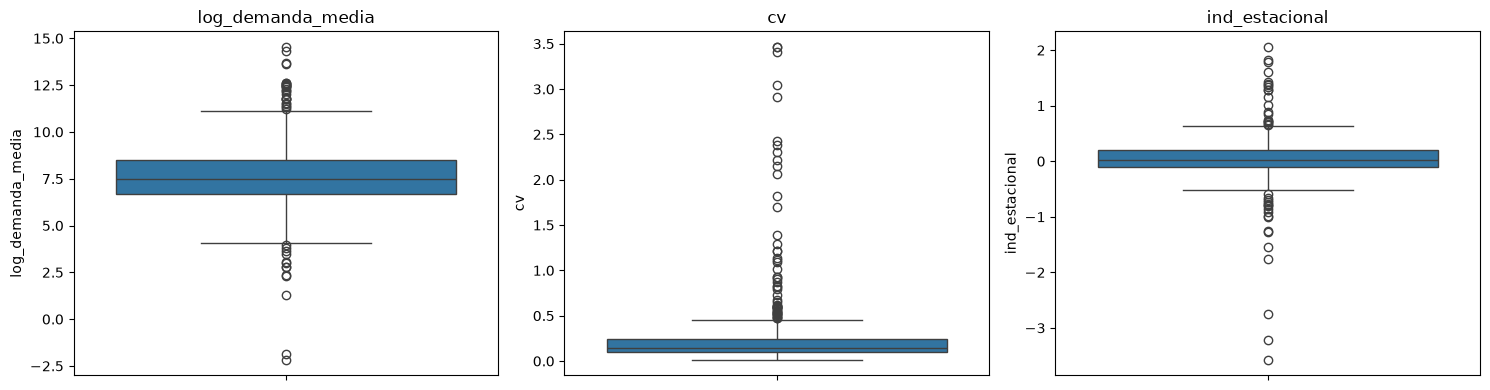

In [32]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

for eje, v in zip(ejes, variables):
    sns.boxplot(y=metricas[v], ax=eje)
    eje.set_title(v)

plt.tight_layout()
plt.show()

Los valores atípicos no son errores de carga sino agentes reales con perfiles de consumo distintos, y se concentran en los tipos de agente minoritarios: el 81 % de los Autogeneradores y el 33 % de los Distribuidores, frente al 11 % de los Grandes Usuarios. Eliminarlos implicaría perder casi toda la clase Autogenerador y distorsionar la comparación con las categorías reales, por lo que se decidió conservarlos.

In [33]:
## Eliminamos la columna de meses con demanda porque se refleja en CV (la itermitencia ya se refleja en CV)
 
metricas = metricas.drop(columns=['meses_con_demanda'])
metricas.head()

,demanda_media,desvio,demanda_max,cv,factor_carga,log_demanda_media,media_verano,media_invierno,ind_estacional
AGENTE NEMO,,,,,,,,,
AARGTAOY,1443.743333,213.290548,1851.39,0.147734,0.779816,7.274995,1730.790000,1317.560000,0.286221
ABRILHCY,1197.181667,204.110262,1609.52,0.170492,0.743813,7.087725,1422.970000,1247.876667,0.146255
ACARQQ3Y,406.798333,91.921379,551.61,0.225963,0.737475,6.008318,326.903333,517.983333,-0.469717
ACARSLSY,394.411667,60.792268,499.20,0.154134,0.790087,5.977395,384.343333,382.620000,0.004369
ACERBR1Y,18403.587500,5981.133519,24746.36,0.324998,0.743689,9.820301,18806.510000,22974.100000,-0.226455


Demanda media, desvío, demanda max, media inv, media verano están reflejadas en CV, factor de carga e ind_estacional.



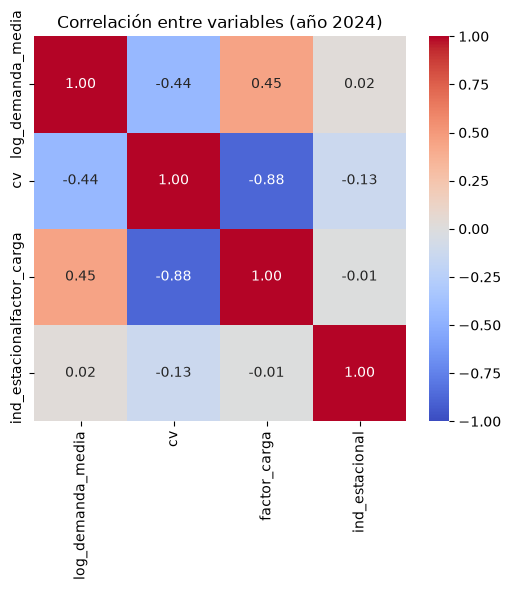

In [34]:
## Heatmap de correlaciones para saber si hay variables que dan la misma info (si la correlación>0,8 dan la misma info)

plt.figure(figsize=(6, 5))
sns.heatmap(
    metricas[variables_modelo].corr(),
    annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1
)
plt.title('Correlación entre variables (año 2024)')
plt.show()

La correlación entre el CV y el factor de carga es −0,88 (en valor absoluto mayor a 0,8): ambas miden en esencia qué tan irregular es el consumo, por lo que se conserva solo el CV. Las demás correlaciones son bajas o moderadas (la mayor, en valor absoluto, es 0,45).

In [35]:
## En el heatmap se ve que CV y factor_carga tienen una correlación alta, así que solo dejamos CV.
## La variables finales son CV, log_demanda_media y el ind_estacional.
## Previo a escalar las variables finales evaluamos si la distribución es normal.

metricas['log_cv'] = np.log(metricas['cv'])

variables_modelo_final = ['log_demanda_media', 'log_cv', 'ind_estacional']

X = metricas[variables_modelo_final]



**ESCALADO**

Asimetría del cv original: 4.75
Asimetría de log_cv: 0.79


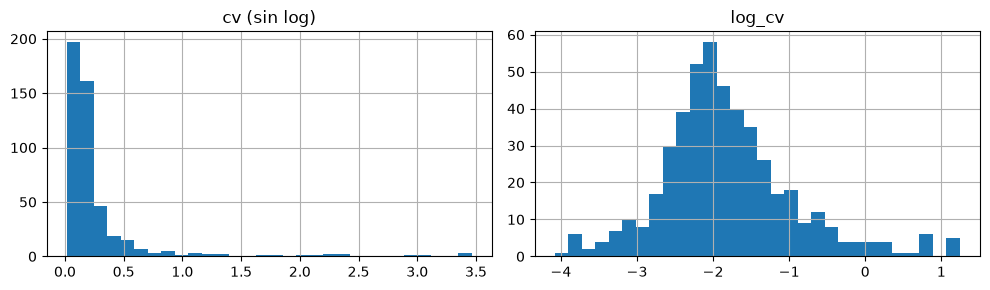

In [36]:
## Comparamos el CV original con el CV transformado con logaritmo.

print("Asimetría del cv original:", round(metricas['cv'].skew(), 2))
print("Asimetría de log_cv:", round(metricas['log_cv'].skew(), 2))

fig, ejes = plt.subplots(1, 2, figsize=(10, 3))

metricas['cv'].hist(bins=30, ax=ejes[0])
ejes[0].set_title('cv (sin log)')

metricas['log_cv'].hist(bins=30, ax=ejes[1])
ejes[1].set_title('log_cv')

plt.tight_layout()
plt.show()

El CV original tiene una distribución muy asimétrica y esa cola larga haría que K-Means (que usa distancias euclidianas) arme clusters para aislar a esos pocos agentes. El logaritmo reduce la asimetría.

log_demanda_media   -0.03
log_cv               0.79
ind_estacional      -1.83
dtype: float64


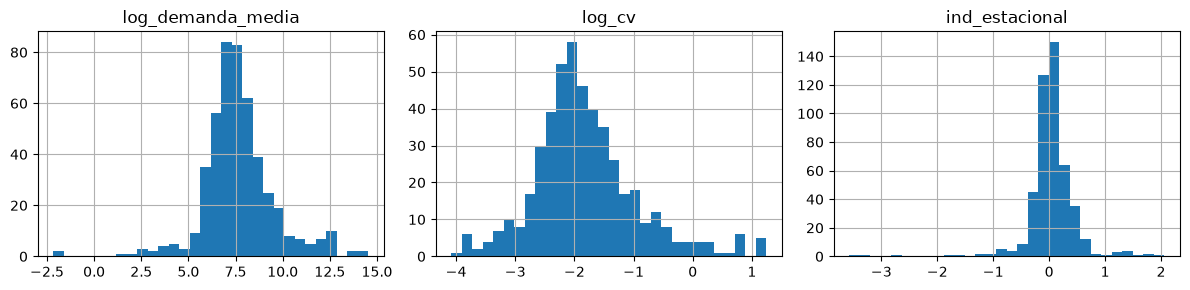

In [37]:
print(metricas[variables_modelo_final].skew().round(2))

metricas[variables_modelo_final].hist(bins=30, figsize=(12, 3), layout=(1, 3))
plt.tight_layout()
plt.show()

El logaritmo reduce de forma marcada la asimetría del CV.

In [66]:
## Usamos RobustScaler.

scaler = RobustScaler()
X_esc = pd.DataFrame(
    scaler.fit_transform(X),
    index=X.index,
    columns=variables_modelo_final
)

print(X_esc.shape)
print(X_esc.median().round(2))
print((X_esc.quantile(0.75) - X_esc.quantile(0.25)).round(2))
print(X_esc.agg(['min', 'max']).round(1))

(474, 3)
log_demanda_media    0.0
log_cv               0.0
ind_estacional      -0.0
dtype: float64
log_demanda_media    1.0
log_cv               1.0
ind_estacional       1.0
dtype: float64
     log_demanda_media  log_cv  ind_estacional
min               -5.4    -2.3           -12.3
max                3.9     3.5             7.0


**MODELO DE APRENDIZAJE NO SUPERVISADO**

In [39]:
## Dejamos listo el df para el modelo de aprendizaje no supervisado.

df_nosup = X_esc.copy()

print(df_nosup.shape)
print()
print(df_nosup.isna().sum())
print()
print(df_nosup.index.duplicated().sum())

df_nosup.head(5)

(474, 3)

log_demanda_media    0
log_cv               0
ind_estacional       0
dtype: int64

0


,log_demanda_media,log_cv,ind_estacional
AGENTE NEMO,,,
AARGTAOY,-0.128558,0.034254,0.887259
ABRILHCY,-0.232821,0.191621,0.407495
ACARQQ3Y,-0.833787,0.501010,-1.703867
ACARSLSY,-0.851004,0.080832,-0.078844
ACERBR1Y,1.288556,0.900210,-0.870041


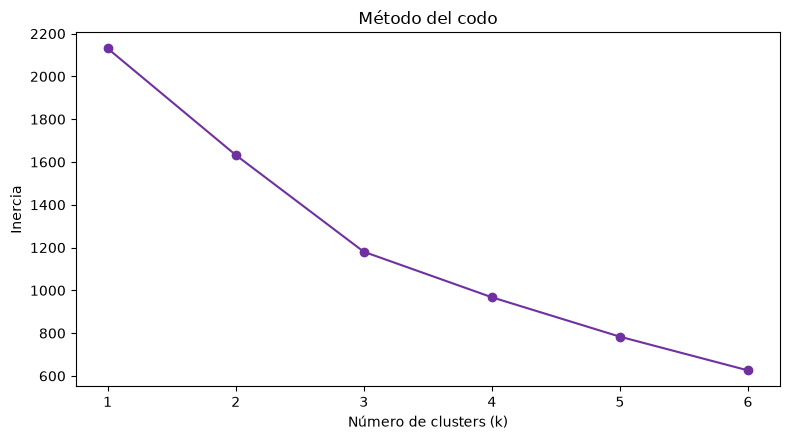

In [ ]:
## Como se trata de variables numéricas continuas, vamos a usar KMeans para identificar patrones de consumo de los agentes.
## Método del codo: para cada k de 1 a 6 se ajusta K-Means (n_init=10: se prueban 10 inicializaciones y se conserva la mejor) y se guarda la inercia.

valores_k = range(1, 7)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(df_nosup).inertia_ for k in valores_k]

plt.figure(figsize=(8, 4.5))
plt.plot(valores_k, inercias, "o-", color="#7030A0")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(list(valores_k))
plt.tight_layout()
plt.show()

El codo se observa en k =3

Considerando los datos originales, comparamos los perfiles de los clusters con k = 3 y 4

Para interpretar los clusters se usan las variables originales (demanda media y CV sin transformar ni escalar) y se comparan los perfiles con k = 3 y k = 4.

In [41]:
for k in [3, 4]:
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(df_nosup)
    perfil = metricas.loc[df_nosup.index].assign(cluster=etiquetas).groupby("cluster")[["demanda_media", "cv", "ind_estacional"]].mean().round(2)
    perfil["agentes"] = pd.Series(etiquetas).value_counts().sort_index()
    print(f"k = {k}")
    display(perfil)

k = 3


,demanda_media,cv,ind_estacional,agentes
cluster,,,,
0,31073.37,0.14,-0.01,370
1,1557.21,0.65,0.55,86
2,1648.22,1.09,-1.34,18


k = 4


,demanda_media,cv,ind_estacional,agentes
cluster,,,,
0,2360.60,0.15,-0.02,304
1,145769.60,0.12,0.04,74
2,1609.26,0.69,0.57,79
3,1707.56,1.10,-1.39,17


**k = 3**

0 = Demanda alta, muy estable (CV 0,14), sin estacionalidad.
1 = Demanda baja, variabilidad media (CV 0,65), estacionalidad marcada positiva (más demanda en verano).
2 = Demanda baja, CV alto (1,09), estacionalidad marcada negativa (más demanda en invierno).

**k = 4**

0 = Demanda media-baja, muy estable (CV 0,15), sin estacionalidad.
1 = Demanda muy alta, muy estable (CV 0,12), sin estacionalidad.
2 = Demanda baja, variabilidad media (CV 0,69), estacionalidad marcada positiva.
3 = Demanda baja, CV alto (1,10), estacionalidad marcada negativa.

----------------------------

El paso de k = 3 a k = 4 separa a los agentes estables según su tamaño: el cluster 0 de k = 3 (370 agentes) se desdobla en gran parte en un grupo de demanda media-baja (304 agentes) y otro de demanda muy alta (74 agentes). Los clusters de estacionalidad positiva (86 → 79 agentes) y negativa con CV alto (18 → 17 agentes) casi no cambian.







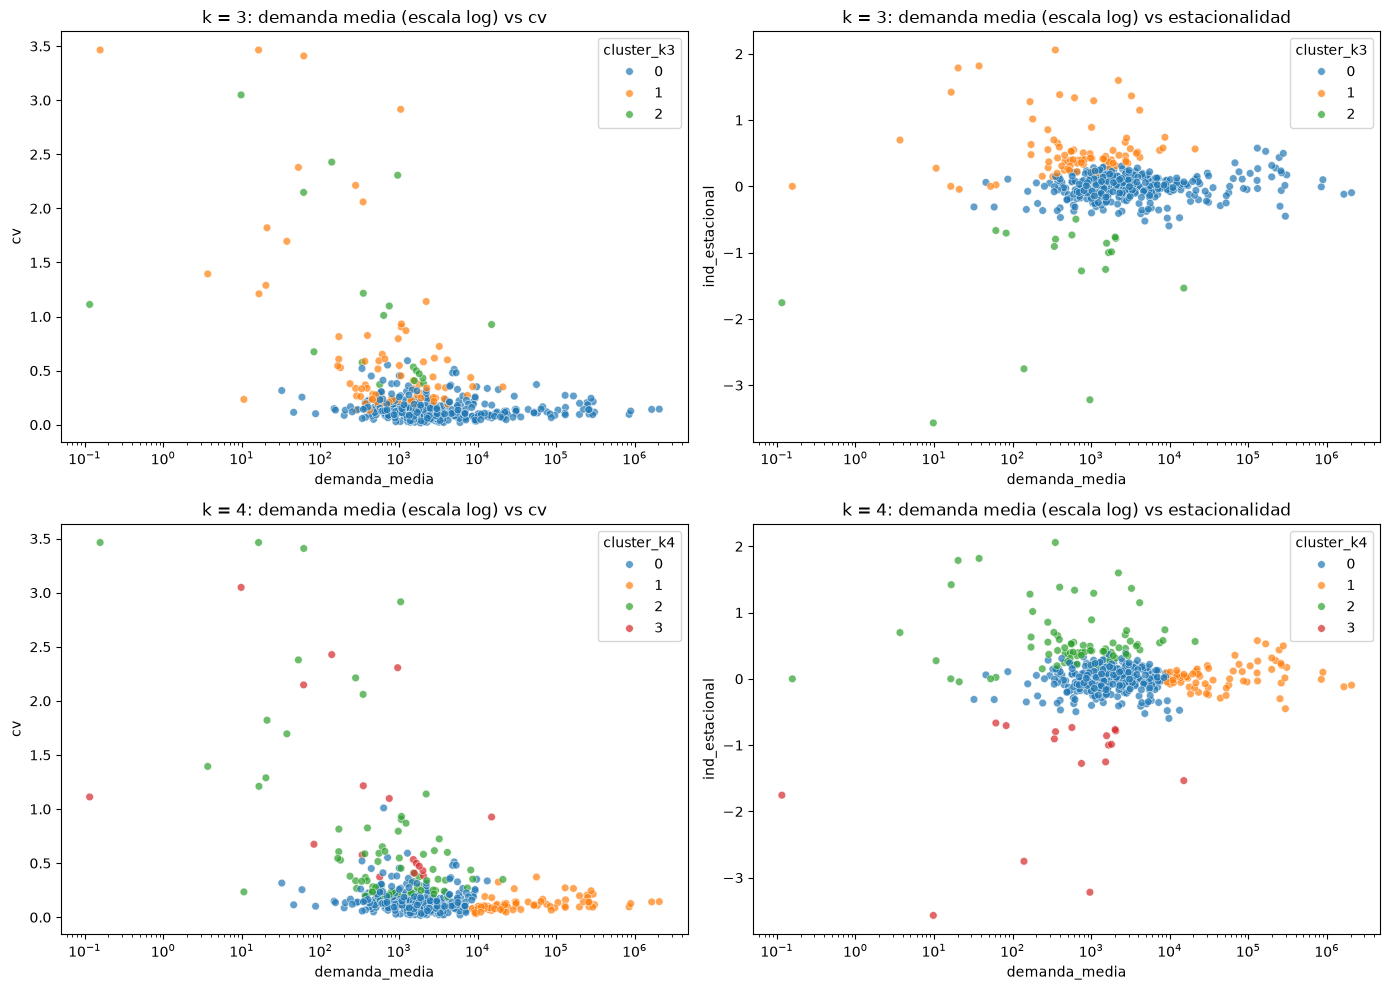

In [67]:
##Gráficos de dispersión para ver cómo se ubican los clusters con las variables originales (demanda en escala logarítmica).
##Fila superior: k = 3. Fila inferior: k = 4. Izquierda: demanda vs CV. Derecha: demanda vs estacionalidad.


datos = metricas.loc[df_nosup.index].copy()

for k in [3, 4]:
    datos[f"cluster_k{k}"] = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(df_nosup)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

for fila, k in enumerate([3, 4]):
    sns.scatterplot(data=datos, x="demanda_media", y="cv", hue=f"cluster_k{k}",
                    palette="tab10", alpha=0.7, s=30, ax=ax[fila, 0])
    ax[fila, 0].set_xscale("log")
    ax[fila, 0].set_title(f"k = {k}: demanda media (escala log) vs cv")

    sns.scatterplot(data=datos, x="demanda_media", y="ind_estacional", hue=f"cluster_k{k}",
                    palette="tab10", alpha=0.7, s=30, ax=ax[fila, 1])
    ax[fila, 1].set_xscale("log")
    ax[fila, 1].set_title(f"k = {k}: demanda media (escala log) vs estacionalidad")

plt.tight_layout()
plt.show()

En k = 4, los clusters se separan principalmente en dos ejes: la demanda media y la estacionalidad.

Con método del codo el quiebre más claro está en k = 3, por lo que se compararon los perfiles de k = 3 y k = 4. Se eligió k = 4 por interpretabilidad. Con k = 3, los agentes estables de tamaño moderado y los de gran tamaño quedan en un mismo cluster, mientras que con k = 4 se separa un grupo de 74 agentes grandes. La elección combina el criterio del codo con la utilidad de los clusters.

**PCA**

Usamos PCA para visualizar las tres variables que usamos para clusterizar en un graf. 2D.



In [68]:
## Ajustamos PCA con 2 componentes sobre df_nosup (variables escaladas).
## explained_variance_ratio_ = proporción de la información (varianza) que retiene cada componente.
## components_ = peso de cada variable en cada componente.

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(df_nosup)

print("Información retenida por cada componente:", pca.explained_variance_ratio_.round(3))
print("Información retenida en total:", pca.explained_variance_ratio_.sum().round(3))

pd.DataFrame(pca.components_, columns=df_nosup.columns, index=["Componente 1", "Componente 2"]).round(2)

Información retenida por cada componente: [0.543 0.319]
Información retenida en total: 0.862


,log_demanda_media,log_cv,ind_estacional
Componente 1,0.04,-0.02,1.00
Componente 2,0.79,-0.62,-0.04


El PCA con dos componentes retiene el 86,2% de la información de las tres variables (54,3% el primer componente y 31,9% el segundo).

El primer componente (54,3 % de la información) corresponde casi enteramente a la estacionalidad (peso 1,00), y separa a los agentes con más demanda en verano de los de invierno. El segundo componente (31,9 %) contrasta demanda media y variabilidad: pesa +0,79 en log_demanda_media y −0,62 en log_cv, por lo que distingue a los agentes grandes y estables de los pequeños y variables. Entre ambos explican el 86,2 % de la información, de modo que el plano que forman es una buena representación de la estructura de los datos. 

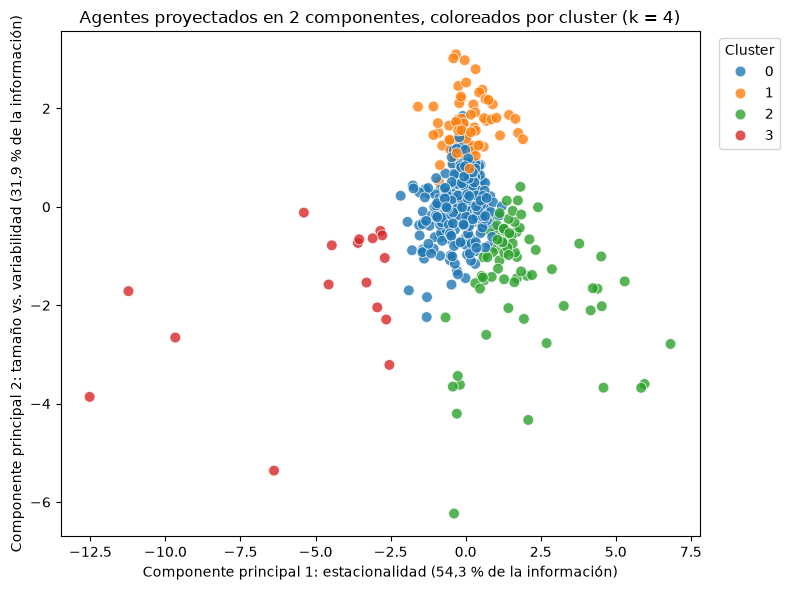

In [69]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=datos["cluster_k4"], palette="tab10", s=60, alpha=0.8)
plt.xlabel("Componente principal 1: estacionalidad (54,3 % de la información)")
plt.ylabel("Componente principal 2: tamaño vs. variabilidad (31,9 % de la información)")
plt.title("Agentes proyectados en 2 componentes, coloreados por cluster (k = 4)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

En el plano de los dos primeros componentes los clusters ocupan regiones distintas. El eje horizontal (estacionalidad) separa al cluster 3 (invierno, a la izquierda) del cluster 2 (verano, a la derecha). El eje vertical (tamaño frente a variabilidad) ubica al cluster 1 (agentes grandes y estables) en la parte superior, mientras que los clusters 2 y 3 se extienden hacia la zona de agentes pequeños y variables. El cluster 0 forma una masa central compacta que se solapa parcialmente con el cluster 1.




In [70]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(df_nosup)
etiquetas = pd.Series(kmeans.labels_, index=df_nosup.index, name="cluster")

print("Inercia:", round(kmeans.inertia_, 1))

originales = metricas.loc[df_nosup.index, ["demanda_media", "cv", "ind_estacional"]]

perfil = originales.groupby(etiquetas).agg(
    agentes=("demanda_media", "size"),
    demanda_media=("demanda_media", "mean"),
    demanda_mediana=("demanda_media", "median"),
    cv=("cv", "mean"),
    ind_estacional=("ind_estacional", "mean"),
).round(2)

perfil["% de agentes"] = (perfil["agentes"] / perfil["agentes"].sum() * 100).round(1)
perfil["% de la demanda"] = (originales.groupby(etiquetas)["demanda_media"].sum() / originales["demanda_media"].sum() * 100).round(1)
perfil

Inercia: 967.7


,agentes,demanda_media,demanda_mediana,cv,ind_estacional,% de agentes,% de la demanda
cluster,,,,,,,
0,304,2360.60,1625.83,0.15,-0.02,64.1,6.2
1,74,145769.60,30500.97,0.12,0.04,15.6,92.5
2,79,1609.26,681.47,0.69,0.57,16.7,1.1
3,17,1707.56,753.24,1.10,-1.39,3.6,0.2


Cluster 0 (64,1 % de los agentes, 6,2 % de la demanda): demanda moderada (mediana 1.626), muy estable (CV 0,15) y sin estacionalidad.
Cluster 1 (15,6 % de los agentes, 92,5 % de la demanda): agentes de gran tamaño (mediana 30.501), muy estables (CV 0,12) y sin estacionalidad.
Cluster 2 (16,7 % de los agentes, 1,1 % de la demanda): demanda baja (mediana 681), variabilidad alta (CV 0,69) y más demanda en verano (índice estacional +0,57).
Cluster 3 (3,6 % de los agentes, 0,2 % de la demanda): demanda baja (mediana 753), variabilidad muy alta (CV 1,10) y más demanda en invierno (índice estacional −1,39).

**Coincidencia con categorías reales**

In [ ]:
## Cruce entre cluster y tipo de agente. Primera tabla: cantidad de agentes. Segunda: porcentaje por fila (cada cluster suma 100).
## El agente DM no tiene clase asignada, por lo que queda fuera (n = 473).

tabla = pd.crosstab(etiquetas, clase[etiquetas.index], rownames=["cluster"], colnames=["tipo de agente"])
print(tabla)
print()
print((tabla.div(tabla.sum(axis=1), axis=0) * 100).round(1))

tipo de agente  Autogenerador  Distribuidor  Gran Usuario
cluster                                                  
0                           3            20           280
1                           2            53            19
2                          18             3            58
3                           8             0             9

tipo de agente  Autogenerador  Distribuidor  Gran Usuario
cluster                                                  
0                         1.0           6.6          92.4
1                         2.7          71.6          25.7
2                        22.8           3.8          73.4
3                        47.1           0.0          52.9


Al comparar los clusters con el tipo de agente (n = 473; DM excluido), se observan asociaciones claras. El cluster 1, de agentes grandes y estables, está compuesto en un 71,6 % por Distribuidores (53 de 74), frente al 16,1 % que representan en la muestra completa, y reúne al 70 % de todos los Distribuidores. El cluster 0 está formado por Grandes Usuarios en un 92,4 %. Los Autogeneradores se concentran en los clusters de comportamiento variable y estacional (26 de 31 en los clusters 2 y 3), en particular el cluster 3, donde son el 47,1 % de 17 agentes, un grupo pequeño que debe interpretarse con cautela. La coincidencia entre clusters y tipos es parcial: el 30 % de los Distribuidores queda fuera del cluster 1, y el cluster 2 sigue siendo mayoritariamente Gran Usuario. Esto indica que el tipo de agente se asocia a patrones de demanda característicos, pero no los determina.

In [72]:
print(df.groupby('AGENTE NEMO')['REGION'].nunique().value_counts())
print(df.groupby('AGENTE NEMO')['CATEGORIA TARIFA'].nunique().value_counts())

REGION
1    556
2      1
Name: count, dtype: int64
CATEGORIA TARIFA
1    480
3     77
Name: count, dtype: int64


In [73]:
## Cruce entre cluster y región. Solo se usan los agentes con una única región (556 de 557).

n_regiones = df.groupby('AGENTE NEMO')['REGION'].nunique()
region = df.drop_duplicates(subset='AGENTE NEMO').set_index('AGENTE NEMO')['REGION']
region = region[n_regiones == 1]

region_agentes = region.reindex(etiquetas.index)

tabla_region = pd.crosstab(etiquetas, region_agentes, rownames=["cluster"], colnames=["región"])
print(tabla_region)
print()
print((tabla_region.div(tabla_region.sum(axis=1), axis=0) * 100).round(1))
print()
print("Distribución general de regiones (%):")
print((region_agentes.value_counts(normalize=True) * 100).round(1))

región   BUENOS AIRES  CENTRO  COMAHUE  CUYO  GRAN BS.AS.  LITORAL  NORESTE  \
cluster                                                                       
0                  58      21       14    14          128       34        6   
1                  28       2        6     8            6        6        4   
2                  11       6        5     7           22        9        4   
3                   5       1        2     0            1        2        1   

región   NOROESTE  PATAGONICA  
cluster                        
0              15          13  
1               6           8  
2              12           3  
3               1           4  

región   BUENOS AIRES  CENTRO  COMAHUE  CUYO  GRAN BS.AS.  LITORAL  NORESTE  \
cluster                                                                       
0                19.1     6.9      4.6   4.6         42.2     11.2      2.0   
1                37.8     2.7      8.1  10.8          8.1      8.1      5.4   
2               

Con la región, la coincidencia es débil.

Cluster 0: predomina el Gran Buenos Aires (42,2 %).
Cluster 1: tiene más agentes de la provincia de Buenos Aires (37,8 %)  y menos del Gran Buenos Aires (8,1 %).
Cluster 2: el Gran Buenos Aires sigue siendo la región más frecuente (27,8 %), y el Noroeste está algo por encima (15,2 %).
Cluster 3: son solo 17 agentes la región más frecuente es la provincia de Buenos Aires (29,4 %), seguida de la región Patagónica (23,5 %).

En conjunto, la región se asocia con los patrones de demanda menos que el tipo de agente.

**Estabilidad del modelo (semillas) - Inicialización**

In [74]:
filas = []
for semilla in range(10):
    km = KMeans(n_clusters=4, n_init=1, random_state=semilla).fit(df_nosup)
    tamanos = sorted(pd.Series(km.labels_).value_counts().tolist(), reverse=True)
    filas.append({"semilla": semilla, "inercia": round(km.inertia_, 1), "tamaños de cluster": tamanos})

pd.DataFrame(filas)

,semilla,inercia,tamaños de cluster
0,0,972.8,"[263, 129, 78, 4]"
1,1,1014.4,"[331, 90, 29, 24]"
2,2,967.7,"[303, 79, 75, 17]"
3,3,987.6,"[273, 116, 81, 4]"
4,4,967.7,"[301, 78, 78, 17]"
5,5,973.2,"[292, 98, 80, 4]"
6,6,990.3,"[262, 180, 17, 15]"
7,7,989.2,"[313, 81, 76, 4]"
8,8,987.5,"[246, 193, 18, 17]"
9,9,968.7,"[290, 91, 76, 17]"


Para evaluar la estabilidad de K-Means con k = 4 se entrenó el modelo con 10 semillas distintas y un solo intento de inicialización (n_init = 1). La solución final (inercia 967,7), obtenida repitiendo 10 inicializaciones y conservando la mejor, tiene tamaños de cluster [304, 79, 74, 17]. La semilla 2 (inercia 967,7) fue igual. En 4 de las 10 semillas (0, 3, 5 y 7) apareció una solución alternativa que aísla a 4 agentes extremos, con inercia mayor (972,8 a 989,2). En las restantes, los tamaños de los clusters variaron según la semilla. La estructura general es estable, pero los límites exactos entre clusters dependen de la inicialización, por lo que se usó n_init = 10.

**ALTERNATIVA**

Segmentación en dos etapas:

1. **Etapa 1:** separamos a los agentes con CV mayor a 1, es decir, aquellos cuyo desvío mensual supera a su demanda media (consumo muy irregular o intermitente). 
2. **Etapa 2:** aplicamos K-Means solo al grupo principal (el resto de los agentes), con las mismas variables (log_demanda_media, log_cv e ind_estacional), escaladas de nuevo solo con este grupo.

El objetivo es ver si, sin los agentes más irregulares, aparecen patrones más finos dentro del grupo principal, y si esos patrones coinciden con el tipo de agente (en particular, Distribuidores y Grandes Usuarios).

In [75]:
## Etapa 1: separamos a los agentes con CV mayor a 1 (su desvío es mayor que su demanda media).

es_extremo = originales["cv"] > 1

print("Agentes separados:", es_extremo.sum(), "de", len(originales))
print("% de la demanda total que representan:",
      round(originales.loc[es_extremo, "demanda_media"].sum() / originales["demanda_media"].sum() * 100, 2))
print("De ellos, intermitentes (menos de 12 meses con demanda):",
      es_extremo[es_extremo].index.isin(intermitentes.index).sum())
print()
print(clase[es_extremo[es_extremo].index].value_counts())

Agentes separados: 21 de 474
% de la demanda total que representan: 0.06
De ellos, intermitentes (menos de 12 meses con demanda): 17

TIPO AGENTE
Autogenerador    17
Gran Usuario      4
Name: count, dtype: int64


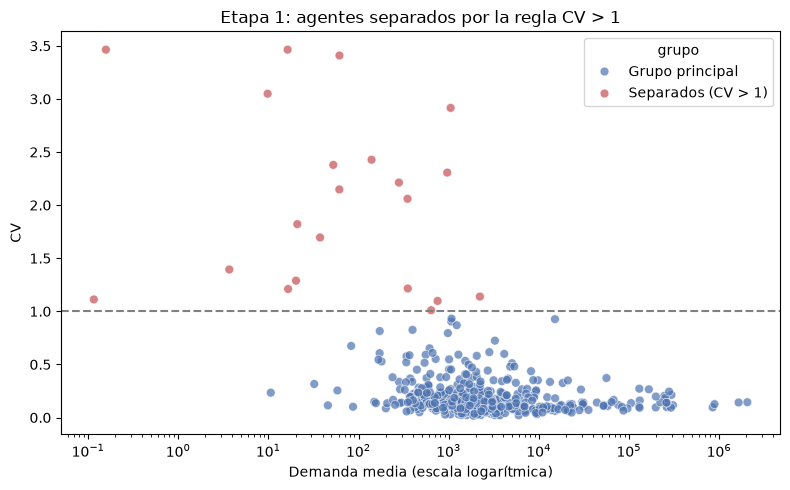

In [79]:
## Gráfico de la etapa 1: qué agentes quedan separados por la regla CV > 1.

datos_e1 = originales.copy()
datos_e1["grupo"] = np.where(es_extremo, "Separados (CV > 1)", "Grupo principal")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=datos_e1, x="demanda_media", y="cv", hue="grupo",
                palette={"Grupo principal": "#4C72B0", "Separados (CV > 1)": "#C44E52"},
                alpha=0.7, s=40)
plt.axhline(1, color="gray", linestyle="--")
plt.xscale("log")
plt.xlabel("Demanda media (escala logarítmica)")
plt.ylabel("CV")
plt.title("Etapa 1: agentes separados por la regla CV > 1")
plt.tight_layout()
plt.show()

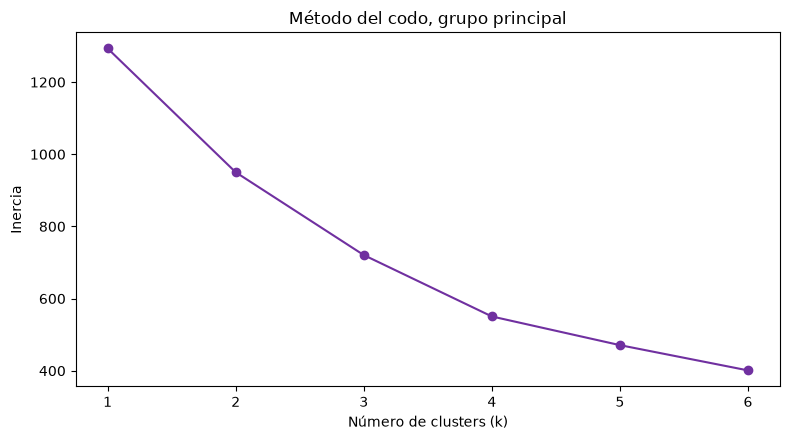

In [76]:
## Etapa 2: K-Means sobre el grupo principal (agentes con CV menor o igual a 1).
## Se escalan de nuevo las variables usando solo este grupo.

principal = originales.index[~es_extremo]

X2 = metricas.loc[principal, variables_modelo_final]
X2_esc = pd.DataFrame(RobustScaler().fit_transform(X2), index=X2.index, columns=variables_modelo_final)

inercias2 = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X2_esc).inertia_ for k in range(1, 7)]

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 7), inercias2, "o-", color="#7030A0")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo, grupo principal")
plt.xticks(range(1, 7))
plt.tight_layout()
plt.show()

La regla de corte (CV mayor a 1) separa 21 agentes (4,4 % de los 474), que representan apenas el 0,06 % de la demanda total. 17 de ellos son agentes intermitentes (de los 18 que hay en total): son 17 Autogeneradores, y 4 Grandes Usuarios, y ningún Distribuidor. En el grupo principal (453 agentes), el método del codo muestra el quiebre más claro en k = 4.

In [77]:
## K-Means con k = 4 sobre el grupo principal.

kmeans2 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X2_esc)
etiquetas2 = pd.Series(kmeans2.labels_, index=X2_esc.index, name="cluster")

print("Inercia:", round(kmeans2.inertia_, 1))

originales2 = originales.loc[principal]

perfil2 = originales2.groupby(etiquetas2).agg(
    agentes=("demanda_media", "size"),
    demanda_media=("demanda_media", "mean"),
    demanda_mediana=("demanda_media", "median"),
    cv=("cv", "mean"),
    ind_estacional=("ind_estacional", "mean"),
).round(2)

perfil2["% de agentes"] = (perfil2["agentes"] / perfil2["agentes"].sum() * 100).round(1)
perfil2["% de la demanda"] = (originales2.groupby(etiquetas2)["demanda_media"].sum() / originales2["demanda_media"].sum() * 100).round(1)
perfil2

Inercia: 550.5


,agentes,demanda_media,demanda_mediana,cv,ind_estacional,% de agentes,% de la demanda
cluster,,,,,,,
0,227,2801.41,2029.62,0.11,0.04,50.1,5.5
1,83,2538.07,1284.33,0.29,-0.32,18.3,1.8
2,62,171944.92,52388.74,0.13,0.05,13.7,91.5
3,81,1808.83,967.37,0.36,0.47,17.9,1.3


Cluster 0 (50,1 % de los agentes del grupo principal, 5,5 % de la demanda): demanda moderada (mediana 2.030), muy estable (CV 0,11) y sin estacionalidad (índice +0,04).
Cluster 1 (18,3 % de los agentes, 1,8 % de la demanda): demanda moderada-baja (mediana 1.284), variabilidad media (CV 0,29) y más demanda en invierno (índice −0,32).
Cluster 2 (13,7 % de los agentes, 91,5 % de la demanda): agentes de gran tamaño (mediana 52.389), muy estables (CV 0,13) y sin estacionalidad (índice +0,05).
Cluster 3 (17,9 % de los agentes, 1,3 % de la demanda): demanda baja (mediana 967), variabilidad media (CV 0,36) y más demanda en verano (índice +0,47).

In [78]:
tabla2 = pd.crosstab(etiquetas2, clase[etiquetas2.index], rownames=["cluster"], colnames=["tipo de agente"])
print(tabla2)
print()
print((tabla2.div(tabla2.sum(axis=1), axis=0) * 100).round(1))

tipo de agente  Autogenerador  Distribuidor  Gran Usuario
cluster                                                  
0                           1            23           202
1                           3             2            78
2                           2            48            12
3                           8             3            70

tipo de agente  Autogenerador  Distribuidor  Gran Usuario
cluster                                                  
0                         0.4          10.2          89.4
1                         3.6           2.4          94.0
2                         3.2          77.4          19.4
3                         9.9           3.7          86.4


Al separar a los agentes más irregulares, el grupo principal (453 agentes) se divide en cuatro clusters. Los Distribuidores se concentran en el cluster 2, de agentes de gran tamaño y muy estables: es un 77,4 % Distribuidores y reúne a 48 de los 76 Distribuidores. Los Grandes Usuarios, en cambio, se reparten en los otros tres clusters (89 a 94 % de Grandes Usuarios), que se diferencian por su variabilidad, su tamaño y su estacionalidad: estables y sin estacionalidad (cluster 0), con más demanda en invierno (cluster 1) y con más demanda en verano (cluster 3). En el modelo con todos los agentes, 280 de los 366 Grandes Usuarios caían en un único cluster de agentes estables y sin estacionalidad; la segunda etapa los reparte entre tres perfiles distintos. La separación entre Distribuidores y Grandes Usuarios es clara pero no total: 12 Grandes Usuarios (19,4 % del cluster 2) tienen un perfil de gran tamaño y estable como los Distribuidores, y 23 Distribuidores (30 %) están en el cluster 0. Quedan solo 14 Autogeneradores, por lo que no se interpretan por separado.

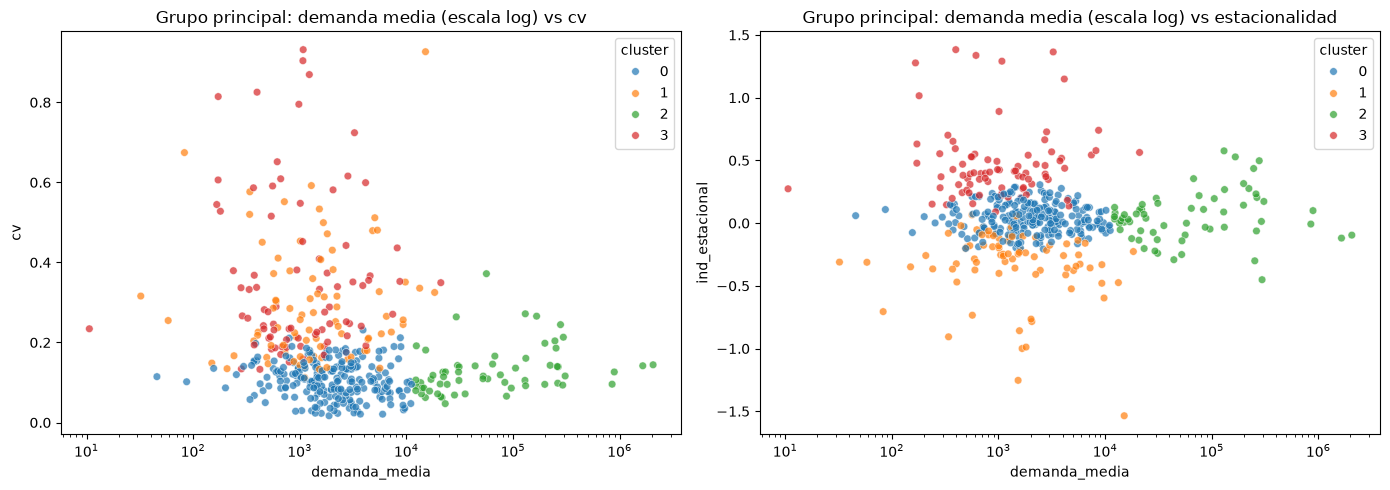

In [80]:
## Gráfico de la etapa 2: clusters del grupo principal (variables originales).

datos2 = originales2.copy()
datos2["cluster"] = etiquetas2

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=datos2, x="demanda_media", y="cv", hue="cluster",
                palette="tab10", alpha=0.7, s=30, ax=ejes[0])
ejes[0].set_xscale("log")
ejes[0].set_title("Grupo principal: demanda media (escala log) vs cv")

sns.scatterplot(data=datos2, x="demanda_media", y="ind_estacional", hue="cluster",
                palette="tab10", alpha=0.7, s=30, ax=ejes[1])
ejes[1].set_xscale("log")
ejes[1].set_title("Grupo principal: demanda media (escala log) vs estacionalidad")

plt.tight_layout()
plt.show()

En el grupo principal, los clusters se separan por tamaño, variabilidad y estacionalidad. El cluster 2 (mayoría de Distribuidores) ocupa la zona de demanda alta con CV bajo. El cluster 0 forma la masa central, CV bajo y estacionalidad cercana a 0. Los clusters 1 y 3 tienen un CV más alto que el cluster 0 y se superponen en ese eje; se distinguen entre sí por la estacionalidad. El cluster 1 tiene índices en su mayoría negativos (más demanda en invierno) y el cluster 3, positivos (más demanda en verano). La frontera entre los clusters 0 y 2 es difusa.

**MODELO DE APRENDIZAJE SUPERVISADO**

La variable objetivo del modelo supervisado es el tipo de agente (TIPO AGENTE), porque es una característica del agente como tal: cada agente del MEM tiene un único valor. En cambio, CATEGORIA DEMANDA y TIPO DEMANDA son propiedades de cada fila (cada registro mensual de demanda), por lo que un mismo agente puede aparecer con más de un valor. Como nuestro DataFrame tiene una fila por agente, necesitamos una etiqueta que sea única por agente.

In [92]:
## Cuántos agentes tienen más de un valor en cada columna.
cols = ['CATEGORIA DEMANDA', 'TIPO DEMANDA', 'CATEGORIA TARIFA']
print((df.groupby('AGENTE NEMO')[cols].nunique() > 1).sum())

CATEGORIA DEMANDA    58
TIPO DEMANDA         77
CATEGORIA TARIFA     77
dtype: int64


In [81]:
## Verificamos que cada agente tenga un solo tipo de agente, que es la variable target

tipo_x_agente = df.groupby('AGENTE NEMO')['TIPO AGENTE'].nunique()
print(tipo_x_agente.value_counts())

TIPO AGENTE
1    557
Name: count, dtype: int64


In [82]:
## Cuántos hay de cada tipo de agente

tipo_x_agente = df.groupby('TIPO AGENTE')['AGENTE NEMO'].nunique()
print(tipo_x_agente)

TIPO AGENTE
AG     36
AR      3
DI     76
DM      1
GU    441
Name: AGENTE NEMO, dtype: int64


In [83]:
solo_ar_dm = df[df['TIPO AGENTE'].isin(['AR', 'DM'])]

una_fila_por_agente = solo_ar_dm.drop_duplicates(subset='AGENTE NEMO')

print(una_fila_por_agente[['AGENTE NEMO', 'AGENTE DESCRIPCION', 'TIPO AGENTE', 'REGION', 'TIPO DEMANDA']])

      AGENTE NEMO              AGENTE DESCRIPCION TIPO AGENTE        REGION  \
731      ALUAREUA     ALUAR SA AUTOGENERADOR REN.          AR    PATAGONICA   
733      AGRIQIDA           AGRITUR SAN LUIS S.A.          AR        CENTRO   
749      CPIEDR1Q        COOPERATIVA DE PIEDRITAS          DM  BUENOS AIRES   
17194    CEMAGIDA  AG CEMENTOS AVELLANEDA S. Luis          AR        CENTRO   

                           TIPO DEMANDA  
731                                GUMA  
733                                GUMA  
749    No Residencial (ESTACIONALIZADA)  
17194                              GUMA  


In [84]:
solo_ag = df[df['TIPO AGENTE'] == 'AG']

una_fila_por_agente_ag = solo_ag.drop_duplicates(subset='AGENTE NEMO')

print(una_fila_por_agente_ag[['AGENTE NEMO', 'AGENTE DESCRIPCION', 'REGION', 'TIPO DEMANDA']].head(15))

    AGENTE NEMO              AGENTE DESCRIPCION        REGION TIPO DEMANDA
22     APARPPNA           ALTO PARANA-PTO.PIRAY       NORESTE         GUMA
36     ARCOLPTA        ARCOR ING.LA PROVIDENCIA      NOROESTE         GUMA
38     ARCOMSXA     ARCOR MARIO SEVESO ARROYITO        CENTRO         GUMA
65     AZUCTETA       AZUCARERA JUAN M.TERAN SA      NOROESTE         GUMA
90     CAPEX-QA        CAPEX S.A. AUTOGENERADOR       COMAHUE         GUMA
161    CHEVHUQA  CHEVRON ARGENTINA - HUANTRAICO       COMAHUE         GUMA
482    IRTABAAA  Ingenio y Ref.S.Martin Tabacal      NOROESTE         GUMA
493    LEDESMYA                    LEDESMA SAAI      NOROESTE         GUMA
535    MRPLSLSA  MOLINOS AGRO AG.(Ex.Mol Rio P)       LITORAL         GUMA
540    NIDEJU1A          NIDERA SAFORCADA-Junin  BUENOS AIRES         GUMA
558    PETRELRA   YAC.ENTRE LOMAS AUTOGENERADOR       COMAHUE         GUMA
603    SEMINOSA           MOLINO JUAN SEMINO SA       LITORAL         GUMA
604    SHELDSCA       SHE

In [93]:
print(df[df['TIPO AGENTE'].isin(['AG', 'AR'])]['TIPO DEMANDA'].value_counts())

TIPO DEMANDA
GUMA    1515
Name: count, dtype: int64


Los tipos **AG** y **AR** tienen muy pocos agentes (36 y 3). Al revisar sus nombres, ambos corresponden a empresas industriales (por ejemplo Arcor, Ledesma, Siderar, Shell, Aluar, Cementos Avellaneda), todas con TIPO DEMANDA GUMA. Por su perfil similar y para evitar clases con casi ningún ejemplo (imposibles de dividir en entrenamiento/prueba y de validar), se unieron en una única clase llamada “Autogenerador”.

El tipo **DM** tiene un único agente. Con una sola observación no se puede estratificar, ni dividir en entrenamiento y prueba, ni validar de forma cruzada, por lo que el modelo no podría aprender ni evaluarse sobre esa clase. Se excluyó del análisis supervisado.

**Gran Usuario** y **Distribuidor** son los dos tipos con más agentes y representan perfiles de consumo distintos (los distribuidores abastecen a poblaciones enteras; los grandes usuarios son consumidores individuales).Además hay que tener en cuenta que son clases **desbalanceadas**.

In [85]:
## Se identifican los agentes del periodo temporal elegido.
## Clase es la variable targuet.

tipo_por_agente = df.drop_duplicates(subset='AGENTE NEMO').set_index('AGENTE NEMO')['TIPO AGENTE']
mapa = {'GU': 'Gran Usuario', 'DI': 'Distribuidor', 'AG': 'Autogenerador', 'AR': 'Autogenerador'}
clase = tipo_por_agente.map(mapa)
print(clase[metricas.index].value_counts(dropna=False))

TIPO AGENTE
Gran Usuario     366
Distribuidor      76
Autogenerador     31
NaN                1
Name: count, dtype: int64


In [86]:
## Df para el modelo de aprendizaje supervisado.

df_sup = metricas[['log_demanda_media', 'cv', 'ind_estacional']].copy()
df_sup['clase'] = clase[df_sup.index]
df_sup = df_sup.dropna(subset=['clase'])

print(df_sup.shape)
print(df_sup['clase'].value_counts())
df_sup.head()

(473, 4)
clase
Gran Usuario     366
Distribuidor      76
Autogenerador     31
Name: count, dtype: int64


,log_demanda_media,cv,ind_estacional,clase
AGENTE NEMO,,,,
AARGTAOY,7.274995,0.147734,0.286221,Gran Usuario
ABRILHCY,7.087725,0.170492,0.146255,Gran Usuario
ACARQQ3Y,6.008318,0.225963,-0.469717,Gran Usuario
ACARSLSY,5.977395,0.154134,0.004369,Gran Usuario
ACERBR1Y,9.820301,0.324998,-0.226455,Gran Usuario


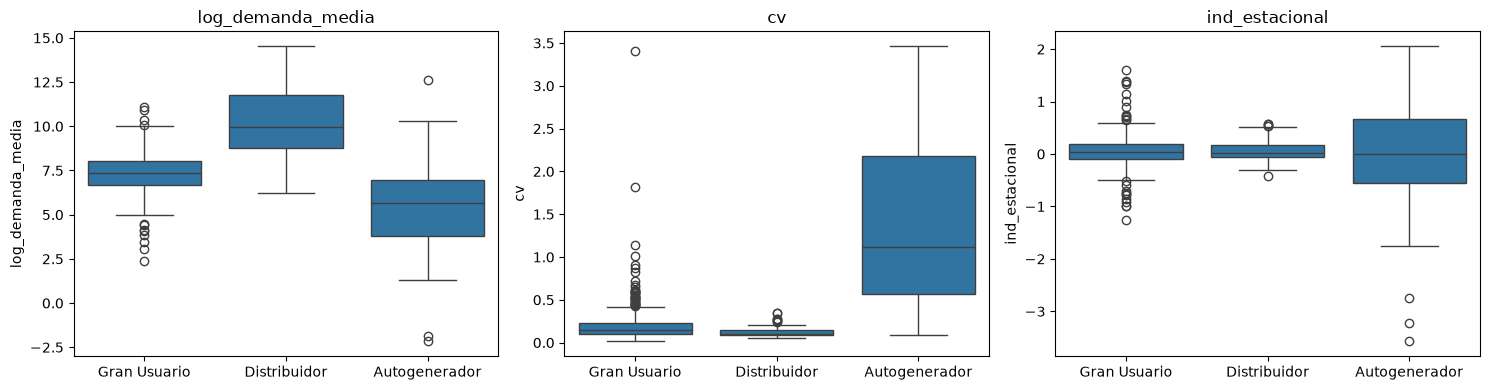

In [87]:
## Boxplots para distinguir si las features se correlacionan con las clases.

orden = ['Gran Usuario', 'Distribuidor', 'Autogenerador']
variables = ['log_demanda_media', 'cv', 'ind_estacional']

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

for eje, variable in zip(ejes, variables):
    sns.boxplot(data=df_sup, x='clase', y=variable, order=orden, ax=eje)
    eje.set_title(variable)
    eje.set_xlabel('')

plt.tight_layout()
plt.show()

Los boxplots por clase muestran que las variables seleccionadas tienen poder discriminante parcial. El nivel de demanda (log_demanda_media) separa a los Distribuidores, que tienen consumos sensiblemente mayores. El coeficiente de variación distingue a los Autogeneradores, con una demanda mucho más irregular. El índice estacional presenta medianas similares en las tres clases, aunque los Autogeneradores tienen una dispersión mucho mayor. Se observan además valores extremos en las tres variables.

In [88]:
## Separamos el df en x e y

X_sup = df_sup.drop(columns=['clase'])
y_sup = df_sup['clase']

print(X_sup.shape)
print(y_sup.shape)

(473, 3)
(473,)


In [89]:
## dividimos en entrenamiento y prueba

X_sup_train, X_sup_test, y_sup_train, y_sup_test = train_test_split(
    X_sup, y_sup, test_size=0.2, random_state=42, stratify=y_sup
)

print(X_sup_train.shape)
print(X_sup_test.shape)
print(y_sup_train.shape)
print(y_sup_test.shape)


(378, 3)
(95, 3)
(378,)
(95,)


In [90]:
## Verificamos proporción de las clases.

print(y_sup_train.value_counts())
print(y_sup_test.value_counts())

clase
Gran Usuario     292
Distribuidor      61
Autogenerador     25
Name: count, dtype: int64
clase
Gran Usuario     74
Distribuidor     15
Autogenerador     6
Name: count, dtype: int64


In [91]:
## Proponemos un modelo base: DummyClassifier
## Si bien calculamos Accuracy, no es la métrica más representativa, porque las clases están desbalanceadas.
## F1 macro porque asigna el mismo peso a cada clase, independientemente de su tamaño.

modelo_base = DummyClassifier(strategy='most_frequent')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_base = cross_val_score(modelo_base, X_sup_train, y_sup_train, cv=cv, scoring='accuracy')
f1_base = cross_val_score(modelo_base, X_sup_train, y_sup_train, cv=cv, scoring='f1_macro')

print('Accuracy promedio:', acc_base.mean().round(3), '| desvío =', acc_base.std().round(3))
print('F1 macro promedio:', f1_base.mean().round(3), '| desvío =', f1_base.std().round(3))

Accuracy promedio: 0.772 | desvío = 0.005
F1 macro promedio: 0.291 | desvío = 0.001


In [59]:
## Comparamos modelos: reg. log., arbol de dec. y random forest.

modelos = {
    'Base (Dummy)': modelo_base,
    'Regresión logística': Pipeline([
        ('escalador', RobustScaler()),
        ('clasificador', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
}

resultados = []
puntajes_por_modelo = {}

for nombre, modelo in modelos.items():
    puntajes = cross_val_score(modelo, X_sup_train, y_sup_train, cv=cv, scoring='f1_macro')
    puntajes_por_modelo[nombre] = puntajes
    resultados.append({'modelo': nombre, 'F1 macro promedio': puntajes.mean(), 'desvío': puntajes.std()})

tabla_modelos = pd.DataFrame(resultados)
print(tabla_modelos.round(3))


                modelo  F1 macro promedio  desvío
0         Base (Dummy)              0.291   0.001
1  Regresión logística              0.661   0.078
2    Árbol de decisión              0.665   0.109
3        Random Forest              0.745   0.072


Random Forest obtuvo el mayor F1 macro promedio (0,745), frente a 0,661 de la regresión logística y 0,665 del árbol de decisión, y los tres superan ampliamente al modelo base (0,291). Sin embargo, los desvíos entre particiones (0,07 a 0,11) son del orden de las diferencias entre modelos.

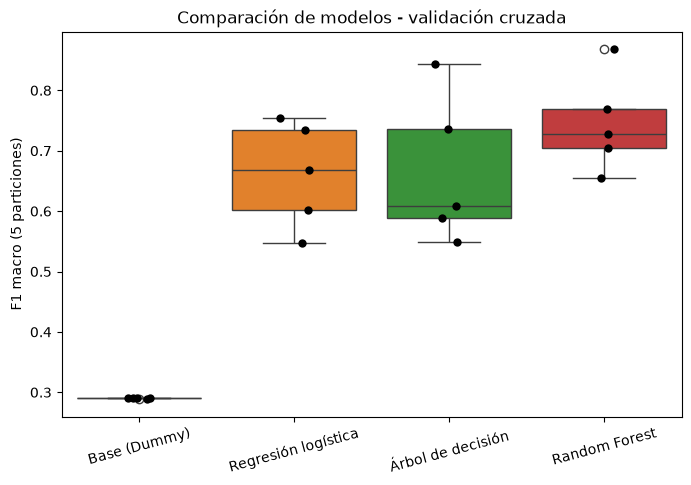

In [60]:
## Evaluar graficamente que modelo es mejor.

tabla_puntajes = pd.DataFrame(puntajes_por_modelo)

plt.figure(figsize=(8, 5))
sns.boxplot(data=tabla_puntajes)
sns.stripplot(data=tabla_puntajes, color='black', size=6)
plt.ylabel('F1 macro (5 particiones)')
plt.title('Comparación de modelos - validación cruzada')
plt.xticks(rotation=15)
plt.show()

No parece haber diferencias claras, sin embrago random forest es el más compacto y tiene un boxplot que alcanza mejor métrica.

Armamos una matriz de confusión 3X3 para ver en que clase se equivoca más el random forest.

               Gran Usuario  Distribuidor  Autogenerador
Gran Usuario            259            21             12
Distribuidor             13            48              0
Autogenerador             6             3             16


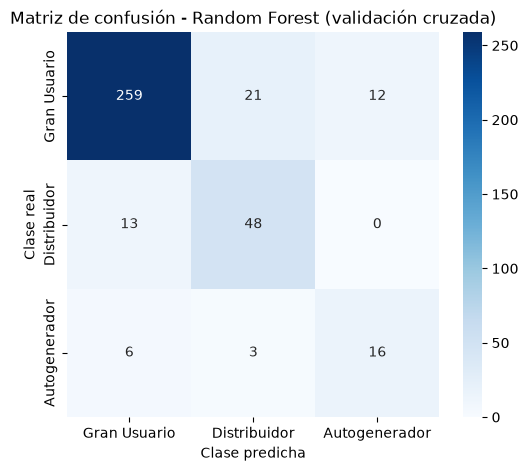

In [61]:
clases_orden = ['Gran Usuario', 'Distribuidor', 'Autogenerador']

modelo_rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
y_pred_cv = cross_val_predict(modelo_rf, X_sup_train, y_sup_train, cv=cv)

matriz = confusion_matrix(y_sup_train, y_pred_cv, labels=clases_orden)
matriz_df = pd.DataFrame(matriz, index=clases_orden, columns=clases_orden)
print(matriz_df)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('Matriz de confusión - Random Forest (validación cruzada)')
plt.show()

La matriz de confusión del Random Forest (validación cruzada sobre el conjunto de entrenamiento) muestra que la clase Gran Usuario se clasifica correctamente en la mayoria de los casos, seguida de Distribuidor y Autogenerador. La mayoría de los errores corresponden a Grandes Usuarios, clasificados como autog. o distrib. También hay Distribuidores (13) y Autogeneradores (6) clasificados como Gran Usuario. La clase Autogenerador, con solo 25 agentes de entrenamiento, es la más difícil de detectar.

Ahora ajustamos los hiperparámetros del random forest, para encontrar los que mejoren las métricas.

In [ ]:
## Usamos gridsearchcv, entre 100 y 300 árboles, entre 3, 5, 8 y ninguna profunfidad max. y un mínimo de muestra entre 1 y 5.

parametros = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [1, 2, 5]
}

busqueda = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=parametros,
    cv=cv,
    scoring='f1_macro'
)
busqueda.fit(X_sup_train, y_sup_train)

print('Mejores parámetros:', busqueda.best_params_)
print('Mejor F1 macro (CV):', round(busqueda.best_score_, 3))
i = busqueda.best_index_
print('Desvío del mejor modelo:', round(busqueda.cv_results_['std_test_score'][i], 3))

Mejores parámetros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
Mejor F1 macro (CV): 0.753
Desvío del mejor modelo: 0.086


El mejor modelo (300 árboles, ninguna profundidad máxima y mínimo de 1 agente por hoja) obtiene un F1 macro de 0,753 en validación cruzada, frente a 0,745 del Random Forest inicial.

Sin embargo la diferencia entre ellas es del orden del desvío entre las particiones.

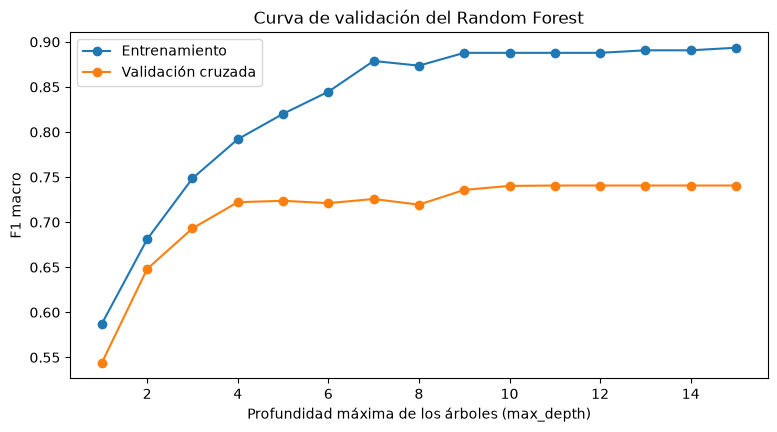

In [94]:
## Curva de validación: F1 macro en entrenamiento y en validación cruzada para distintas profundidades máximas (200 árboles, mínimo de 2 agentes por hoja).
## Sirve para detectar sobreajuste: el F1 en entrenamiento se calcula sobre los mismos datos con los que se entrenó.

profundidades = range(1, 16)
f1_tr, f1_cv = [], []

for d in profundidades:
    rf = RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=2,
                                class_weight='balanced', random_state=42)
    f1_cv.append(cross_val_score(rf, X_sup_train, y_sup_train, cv=cv, scoring='f1_macro').mean())
    rf.fit(X_sup_train, y_sup_train)
    f1_tr.append(f1_score(y_sup_train, rf.predict(X_sup_train), average='macro'))

plt.figure(figsize=(9, 4.5))
plt.plot(profundidades, f1_tr, 'o-', label='Entrenamiento')
plt.plot(profundidades, f1_cv, 'o-', label='Validación cruzada')
plt.xlabel('Profundidad máxima de los árboles (max_depth)')
plt.ylabel('F1 macro')
plt.title('Curva de validación del Random Forest')
plt.legend()
plt.show()

La curva de validación muestra que, al aumentar la profundidad de los árboles, el F1 de entrenamiento (sin CV) sube hasta aprox. 0,90, mientras que el de validación cruzada se estabiliza en aprox. 0,75 desde profundidad 4. Hay cierta diferencia entre ambos (overfitting).

F1 macro en test: 0.745
               precision    recall  f1-score   support

 Gran Usuario       0.92      0.82      0.87        74
 Distribuidor       0.50      0.73      0.59        15
Autogenerador       0.71      0.83      0.77         6

     accuracy                           0.81        95
    macro avg       0.71      0.80      0.75        95
 weighted avg       0.84      0.81      0.82        95

               Gran Usuario  Distribuidor  Autogenerador
Gran Usuario             61            11              2
Distribuidor              4            11              0
Autogenerador             1             0              5


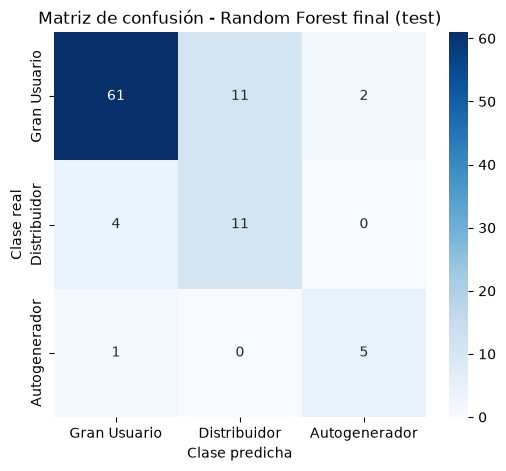

In [95]:
## ## Evaluación del modelo final con los datos de prueba (test), que no se usaron para entrenar ni para elegir hiperparámetros.

modelo_final = busqueda.best_estimator_
y_pred_test = modelo_final.predict(X_sup_test)

print('F1 macro en test:', round(f1_score(y_sup_test, y_pred_test, average='macro'), 3))
print(classification_report(y_sup_test, y_pred_test, labels=clases_orden))

matriz_test = confusion_matrix(y_sup_test, y_pred_test, labels=clases_orden)
matriz_test_df = pd.DataFrame(matriz_test, index=clases_orden, columns=clases_orden)
print(matriz_test_df)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_test_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('Matriz de confusión - Random Forest final (test)')
plt.show()

En el conjunto de prueba (95 agentes) el Random Forest final obtiene un F1 macro de 0,745. Por clase, Gran Usuario tiene precisión 0,92 y sensibilidad 0,82; Distribuidor, 0,50 y 0,73; y Autogenerador, 0,71 y 0,83. La precisión de Distribuidor es la más baja: de 22 agentes predichos como Distribuidor, solo 11 lo son, porque 11 Grandes Usuarios se clasificaron como Distribuidor. Autogenerador tiene solo 6 agentes en el conjunto de prueba, por lo que sus métricas son muy poco precisas.

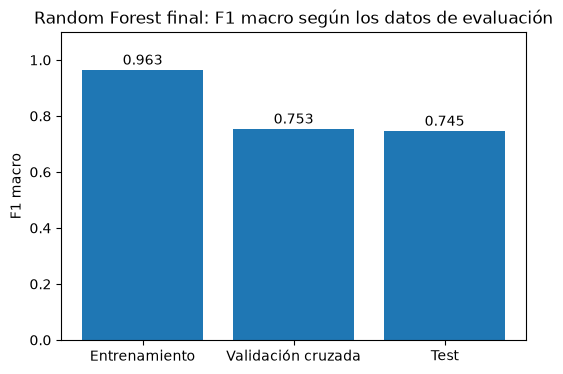

In [ ]:
f1_entrenamiento = f1_score(y_sup_train, modelo_final.predict(X_sup_train), average='macro')
f1_validacion = busqueda.best_score_
f1_test = f1_score(y_sup_test, modelo_final.predict(X_sup_test), average='macro')

etapas = ['Entrenamiento', 'Validación cruzada', 'Test']
valores = [f1_entrenamiento, f1_validacion, f1_test]
plt.figure(figsize=(6, 4))
plt.bar(etapas, valores)
for i, valor in enumerate(valores):
    plt.text(i, valor + 0.02, round(valor, 3), ha='center')
plt.ylim(0, 1.1)
plt.ylabel('F1 macro')
plt.title('Random Forest final: F1 macro según los datos de evaluación')
plt.show()

El Random Forest final obtuvo un F1 macro de 0,963 en el conjunto de entrenamiento, 0,753 en validación cruzada y 0,745 en el conjunto de prueba. La diferencia entre entrenamiento y validación indica sobreajuste. El desempeño en prueba es similar al de validación cruzada, lo que sugiere que el modelo se comporta de forma consistente con agentes no vistos durante el entrenamiento; sin embargo, el conjunto de prueba es pequeño (95 agentes, 6 de ellos Autogeneradores), por lo que esa estimación es poco precisa.

**CONCLUSIONES**

Existen grupos de agentes del MEM con patrones de demanda mensual similares. Con K-Means (k = 4) sobre el nivel de demanda, la variabilidad (log del CV) y la estacionalidad, se identificaron cuatro grupos: agentes de demanda moderada y estable (64,1 % de los agentes, 6,2 % de la demanda); agentes grandes y estables (15,6 % de los agentes, pero 92,5 % de la demanda); agentes pequeños y variables con más demanda en verano (16,7 %); y agentes pequeños y muy variables con más demanda en invierno (3,6 %).

**Coincidencia con categorías reales.** La coincidencia es clara con el tipo de agente y débil con la región. El grupo de agentes grandes y estables está compuesto en un 71,6 % por Distribuidores y reúne al 70 % de todos los Distribuidores; los grupos restantes son mayoritariamente Grandes Usuarios, y los Autogeneradores se concentran en los grupos variables y estacionales. La coincidencia no es total: el tipo de agente se asocia a patrones de demanda característicos, pero no los determina.

**Transformación del CV y alternativa en dos etapas.** La transformación logarítmica del CV evitó que K-Means dedicara clusters a aislar casos extremos: el cluster mayoritario pasó de concentrar el 88 % de los agentes a concentrar el 64 %. Como alternativa, se separaron los 21 agentes con CV mayor a 1 (0,06 % de la demanda) y se aplicó K-Means al grupo principal: los Distribuidores quedaron concentrados en un cluster (77,4 %), mientras que los Grandes Usuarios se repartieron en tres perfiles que se diferencian por variabilidad, tamaño y estacionalidad.

**Modelo supervisado.** Un Random Forest que clasifica el tipo de agente con las mismas variables obtuvo un F1 macro de 0,753 en validación cruzada y 0,745 en prueba, frente a 0,291 del modelo base. La clase Distribuidor tiene una precisión baja (0,50) y los resultados de Autogenerador son poco precisos por su escaso número de agentes.

**Limitaciones.** El análisis usa un único año (2024) y solo agentes con registro en los 12 meses. Para los agentes intermitentes, las métricas se calculan sobre pocos meses. El índice estacional conserva valores extremos aun después del escalado. La elección de k = 4 combina el método del codo con la interpretabilidad, y la estabilidad con distintas inicializaciones muestra que la estructura general se mantiene, aunque los límites exactos entre clusters varían. Finalmente, las clases Autogenerador (31 agentes, resultado de unir AG y AR) y el conjunto de prueba (95 agentes) son pequeños, por lo que las concluiones sobre ellas deben considerarse con precaución.